# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** Line chart

- The question relates to change over time and line graphs do this best.
- The continents have been broken down using their 1970 populations so that all lines begin at 1× and can be compared easily.
- Africa is orange while the others are grey, making the faster growing continent obvious.
- Labels have been added to the end of the lines so there is no legend.
- Dotted line at 1× represents "same size as 1970."

Continent
Europe           1.13
North America    1.90
Asia             2.20
South America    2.26
Oceania          2.31
Africa           3.90
Name: Growth, dtype: float64


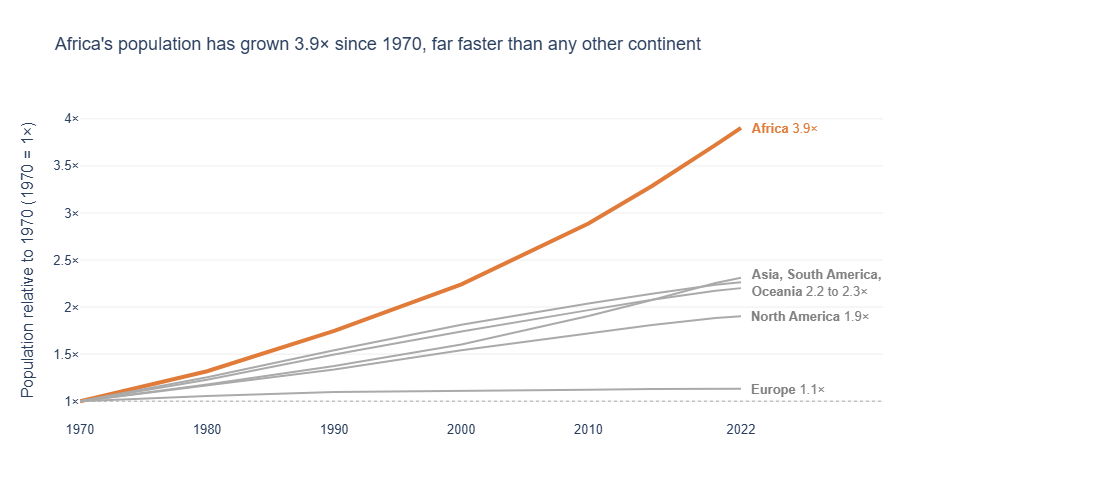

In [2]:
# Q1
# Course palette (CVD-safe): blue, orange, yellow, greys. Africa = orange, Asia = blue, Europe = yellow throughout the notebook
BLUE, ORANGE, YELLOW = '#2E75B6', '#E07B39', '#F5C842'
GREY, LIGHT_GREY = '#AAAAAA', '#DDDDDD'

# step 1: prep data, continent totals per year divided by their own 1970 total
cont = df_long.groupby(['Continent', 'Year'], as_index=False)['Population'].sum()
base_1970 = cont.loc[cont['Year'] == 1970].set_index('Continent')['Population']
cont['Growth'] = cont['Population'] / cont['Continent'].map(base_1970)

end = cont.loc[cont['Year'] == 2022].set_index('Continent')['Growth'].sort_values()
fastest = end.idxmax()
print(end.round(2))

# step 2: plotly express figure
fig = px.line(
    data_frame=cont,
    x='Year', y='Growth',
    color='Continent',
    color_discrete_map={c: (ORANGE if c == fastest else GREY) for c in cont['Continent'].unique()},
    hover_name='Continent',
    hover_data={'Continent': False, 'Growth': ':.2f', 'Population': ':,'},
    labels={'Growth': 'Population relative to 1970 (1970 = 1×)'},
    title=f"{fastest}'s population has grown {end[fastest]:.1f}× since 1970, far faster than any other continent",
    template='plotly_white',
    height=500
)

# step 3: customisation
fig.update_traces(line_width=2)
fig.update_traces(line_width=4, selector={'name': fastest})

# reference line: 1× = same size as in 1970
fig.add_hline(y=1, line_dash='dot', line_color=GREY, line_width=1)

# direct labels instead of a legend; the three continents that end at ~2.2× share one label
cluster = ['Asia', 'South America', 'Oceania']
for c in ['Africa', 'North America', 'Europe']:
    fig.add_annotation(x=2022, y=end[c], text=f'<b>{c}</b> {end[c]:.1f}×', showarrow=False,
                       xanchor='left', xshift=8,
                       font=dict(color=ORANGE if c == fastest else 'grey', size=13))
fig.add_annotation(x=2022, y=end[cluster].mean(),
                   text=f'<b>Asia, South America,<br>Oceania</b> {end[cluster].min():.1f} to {end[cluster].max():.1f}×',
                   showarrow=False, xanchor='left', xshift=8, align='left',
                   font=dict(color='grey', size=13))

fig.update_layout(
    showlegend=False,
    font=dict(family='Arial', size=13),
    margin=dict(r=210),
    xaxis=dict(showgrid=False, title='', tickvals=[1970, 1980, 1990, 2000, 2010, 2022]),
    yaxis=dict(gridcolor='#EEEEEE', ticksuffix='×', range=[0.8, 4.2])
)

fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** Sorted horizontal bar chart

- Bars are the simplest method for comparing and ordering the countries.
- Arranged in descending order, making it easy to see how they are ranked.
- Horizontal for easier readability of the countries’ names.
- Countries in Africa are colored orange, and it is easy to count them (4).
- Values are shown in bars, meaning that there is no need for an x-axis. Bars begin from zero.

           Country      Continent      Added
92           India           Asia  859671872
41           China           Asia  603352887
156       Pakistan           Asia  176533990
149        Nigeria         Africa  162971948
93       Indonesia           Asia  160272945
221  United States  North America  137961517
27          Brazil  South America  118943623
16      Bangladesh           Asia  103644512
63        Ethiopia         Africa   95071678
55        DR Congo         Africa   78858479
163    Philippines           Asia   78123423
131         Mexico  North America   77214819
57           Egypt         Africa   76208117
94            Iran           Asia   60100865
228        Vietnam           Asia   56258007


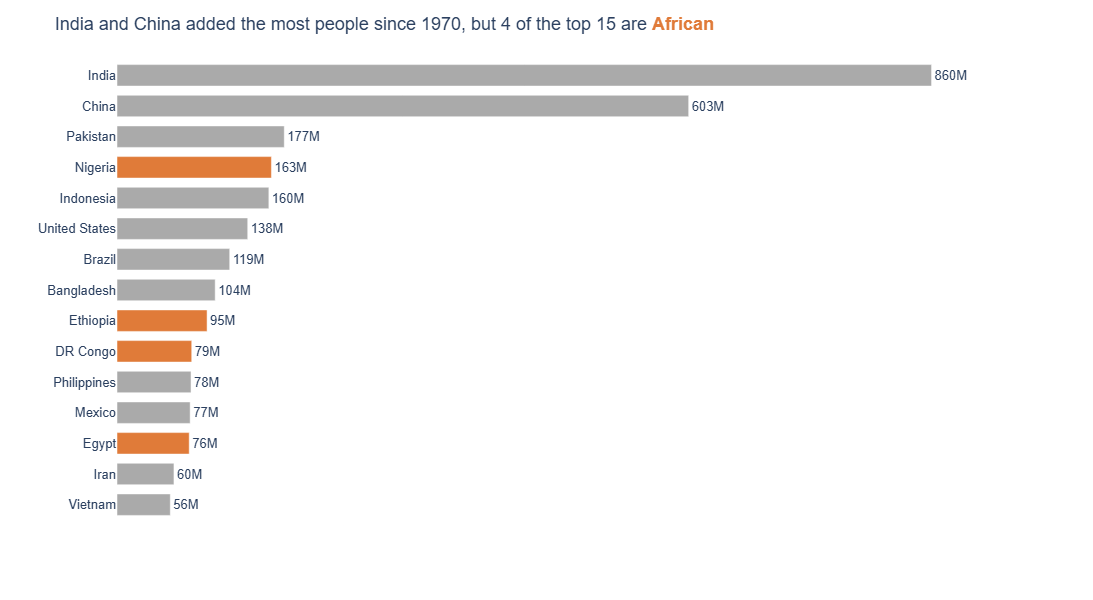

In [3]:
# Q2
# step 1: prep data, people added between 1970 and 2022
df['Added'] = df['2022 Population'] - df['1970 Population']
top15 = df.nlargest(15, 'Added').copy()
top15['Group'] = np.where(top15['Continent'] == 'Africa', 'Africa', 'Other continents')
top15['Label'] = (top15['Added'] / 1e6).map('{:,.0f}M'.format)
n_africa = (top15['Group'] == 'Africa').sum()
print(top15[['Country', 'Continent', 'Added']])

# step 2: plotly express figure
fig = px.bar(
    data_frame=top15,
    x='Added', y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={'Africa': ORANGE, 'Other continents': GREY},
    text='Label',
    hover_data={'Group': False, 'Label': False, 'Continent': True, 'Added': ':,'},
    labels={'Added': 'People added 1970 to 2022', 'Country': ''},
    template='plotly_white',
    height=600
)

# step 3: customisation
fig.update_traces(textposition='outside', cliponaxis=False)

fig.update_layout(
    title=(f"India and China added the most people since 1970, but {n_africa} of the top 15 are "
           f"<span style='color:{ORANGE}'><b>African</b></span>"),
    showlegend=False,
    font=dict(family='Arial', size=13),
    bargap=0.3,
    xaxis=dict(visible=False, range=[0, top15['Added'].max() * 1.1]),   # zero baseline
    yaxis=dict(title='', categoryorder='total ascending')               # largest at the top
)

fig.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** Scatter plot (log scales), one panel per continent

- Scatter plot demonstrates the association between two variables, namely area and population.
- Log scale is used on both axes since there is a great variability in values – from small islands to Russia.
- Dashed line represents the global trend while points above it have higher population than expected based on their size.
- Each subplot represents one continent in blue colour while all other countries are shown in grey (it is easier to understand than using six different colours in one diagram).
- Only countries deviating from the trend are marked.

correlation (log-log): 0.87
Continent
Asia             2.21
Europe           1.14
Africa           1.11
North America    1.09
South America    0.49
Oceania          0.43
Name: Residual, dtype: float64


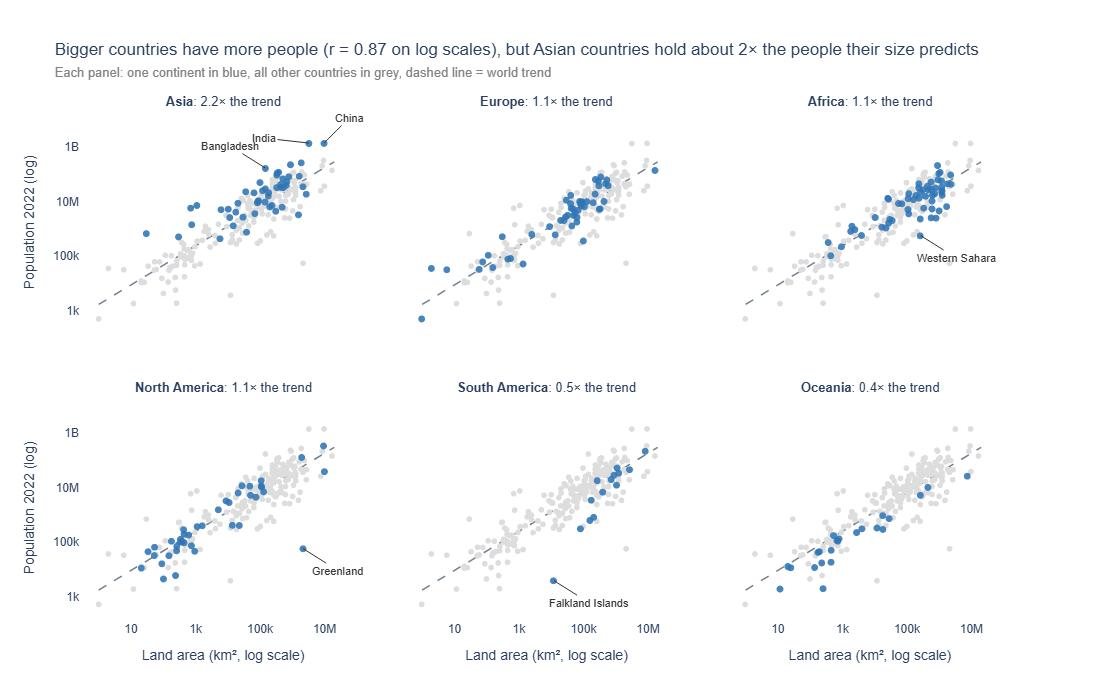

In [4]:
# Q3
import plotly.graph_objects as go

# step 1: prep data
d = df[['Country', 'Continent', 'Area', '2022 Population']].rename(columns={'2022 Population': 'Population'})
log_area, log_pop = np.log10(d['Area']), np.log10(d['Population'])
slope, intercept = np.polyfit(log_area, log_pop, 1)            # world trend on log-log scale
d['Residual'] = log_pop - (intercept + slope * log_area)       # > 0 = more people than the trend predicts
r = np.corrcoef(log_area, log_pop)[0, 1]
print(f'correlation (log-log): {r:.2f}')

# typical country per continent vs the trend: 10 ** median residual (2 = twice as many people as expected)
vs_trend = (10 ** d.groupby('Continent')['Residual'].median()).sort_values(ascending=False)
panel_name = {c: f'<b>{c}</b>: {v:.1f}× the trend' for c, v in vs_trend.items()}
print(vs_trend.round(2))

# every panel: all countries in grey (context) + that continent's countries (focus)
context = pd.concat([d.assign(Panel=panel_name[c], Role='Other countries') for c in vs_trend.index])
focus = d.assign(Panel=d['Continent'].map(panel_name), Role='Continent')
plot_df = pd.concat([context, focus])

# countries that break the pattern most (area over 10,000 km² so city-states don't crowd the labels)
big = d.loc[d['Area'] >= 10_000]
breakers = pd.concat([big.nlargest(3, 'Residual'), big.nsmallest(3, 'Residual')])

# step 2: plotly express figure
fig = px.scatter(
    data_frame=plot_df,
    x='Area', y='Population',
    facet_col='Panel', facet_col_wrap=3,
    facet_row_spacing=0.12, facet_col_spacing=0.04,
    color='Role',
    color_discrete_map={'Other countries': LIGHT_GREY, 'Continent': BLUE},
    category_orders={'Panel': list(panel_name.values()), 'Role': ['Other countries', 'Continent']},
    log_x=True, log_y=True,
    hover_name='Country',
    hover_data={'Role': False, 'Panel': False, 'Area': ':,', 'Population': ':,'},
    labels={'Area': 'Land area (km², log scale)', 'Population': 'Population 2022 (log)'},
    template='plotly_white',
    height=700
)

# step 3: customisation
fig.update_traces(marker=dict(size=7, opacity=0.85))
fig.update_traces(selector={'name': 'Other countries'}, marker=dict(size=6, opacity=1), hoverinfo='skip', hovertemplate=None)

# world trend line in every panel
xs = np.logspace(0, 7.3, 50)
fig.add_trace(go.Scatter(x=xs, y=10 ** (intercept + slope * np.log10(xs)), mode='lines',
                         line=dict(color='slategrey', dash='dash', width=1.5),
                         hoverinfo='skip', showlegend=False), row='all', col='all')

# facet titles: drop the 'Panel=' prefix
fig.for_each_annotation(lambda a: a.update(text=a.text.split('=')[-1], font=dict(size=13)))

# direct labels for the pattern breakers, placed in their own continent's panel
# map continent -> subplot axes, using the first country of each blue (focus) trace
axes_of = {}
for t in fig.data:
    if t.name == 'Continent':
        cont_name = d.loc[d['Country'] == t.hovertext[0], 'Continent'].iloc[0]
        axes_of[cont_name] = (t.xaxis, t.yaxis)
offsets = {'China': (25, -25), 'India': (-45, -5)}     # nudge labels that would overlap
for _, row in breakers.iterrows():
    xa, ya = axes_of[row['Continent']]
    above = row['Residual'] > 0
    dx, dy = offsets.get(row['Country'], (-35, -22) if above else (35, 22))
    fig.add_annotation(x=np.log10(row['Area']), y=np.log10(row['Population']), xref=xa, yref=ya,
                       text=row['Country'], showarrow=True, arrowhead=0, arrowcolor='#333333',
                       ax=dx, ay=dy,
                       font=dict(size=11, color='#333333'))

fig.update_xaxes(showgrid=False, tickvals=[10, 1e3, 1e5, 1e7], ticktext=['10', '1k', '100k', '10M'])
fig.update_yaxes(showgrid=False, tickvals=[1e3, 1e5, 1e7, 1e9], ticktext=['1k', '100k', '10M', '1B'])
fig.update_layout(
    title=(f"Bigger countries have more people (r = {r:.2f} on log scales), but Asian countries hold about "
           f"{vs_trend['Asia']:.0f}× the people their size predicts<br>"
           "<span style='font-size:13px;color:grey'>Each panel: one continent in blue, all other countries in grey, "
           "dashed line = world trend</span>"),
    showlegend=False,
    font=dict(family='Arial', size=12),
    margin=dict(t=110)
)

fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** Box plot (log scale)

- Box plot depicts median and spread for each continent and not the mean value.
- More useful compared to the violin since some continents have fewer countries (14 in South America).
- Logarithmic scale due to presence of city-states that are many times more dense than other cities.
- Arranged according to median with North America having the highest median value depicted in blue color while others in gray.
- Dashed line represents the world median while the outliers are identified.

Continent
North America    221.4
Asia             123.0
Europe           106.9
Oceania           78.2
Africa            59.7
South America     17.8
Name: Density, dtype: float64
               min      max
Continent                  
Africa         2.2    871.9
Asia           2.2  23172.3
Europe         3.6  18234.5
North America  0.0   1299.3
Oceania        3.4    603.2
South America  0.3     65.0


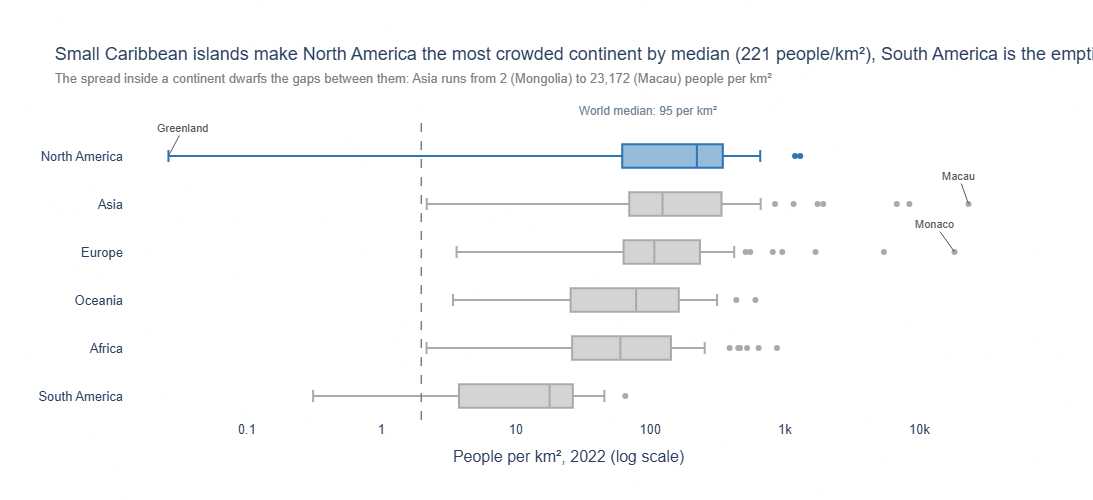

In [5]:
# Q4
# step 1: prep data
med = df.groupby('Continent')['Density'].median().sort_values(ascending=False)
most_crowded = med.idxmax()
world_median = df['Density'].median()
df['Highlight'] = np.where(df['Continent'] == most_crowded, most_crowded, 'Other')
asia_min, asia_max = df.loc[df['Continent'] == 'Asia', 'Density'].agg(['min', 'max'])
print(med.round(1))
print(df.groupby('Continent')['Density'].agg(['min', 'max']).round(1))

# step 2: plotly express figure
fig = px.box(
    data_frame=df,
    x='Density', y='Continent',
    orientation='h',
    color='Highlight',
    color_discrete_map={most_crowded: BLUE, 'Other': GREY},
    category_orders={'Continent': med.index.tolist()},     # highest median at the top
    points='outliers',
    log_x=True,
    hover_name='Country',
    hover_data={'Highlight': False, 'Density': ':,.1f'},
    labels={'Density': 'People per km², 2022 (log scale)', 'Continent': ''},
    template='plotly_white',
    height=500
)

# step 3: customisation
# shapes and annotations on a log axis take log10 values
fig.add_vline(x=np.log10(world_median), line_dash='dash', line_color='slategrey', line_width=1.5,
              annotation=dict(text=f'World median: {world_median:.0f} per km²',
                              font=dict(color='slategrey', size=12), yanchor='bottom'),
              annotation_position='top')

# name the extremes
for country, ax, ay in [('Macau', -10, -28), ('Monaco', -20, -28), ('Greenland', 15, -28)]:
    row = df.loc[df['Country'] == country].iloc[0]
    fig.add_annotation(x=np.log10(row['Density']), y=row['Continent'], text=country,
                       showarrow=True, arrowhead=0, arrowcolor='#555555', ax=ax, ay=ay,
                       font=dict(size=11, color='#555555'))

fig.update_layout(
    title=(f"Small Caribbean islands make {most_crowded} the most crowded continent by median "
           f"({med[most_crowded]:.0f} people/km²), South America is the emptiest ({med.iloc[-1]:.0f})<br>"
           f"<span style='font-size:13px;color:grey'>The spread inside a continent dwarfs the gaps between them: "
           f"Asia runs from {asia_min:.0f} (Mongolia) to {asia_max:,.0f} (Macau) people per km²</span>"),
    boxmode='overlay',               # one box per row, not offset by colour group
    showlegend=False,
    font=dict(family='Arial', size=13),
    xaxis=dict(showgrid=False, tickvals=[0.1, 1, 10, 100, 1000, 10000], ticktext=['0.1', '1', '10', '100', '1k', '10k']),
    yaxis=dict(showgrid=False),
    margin=dict(t=120)
)

fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** Choropleth map

- As the question requires the place, it is better to use the map.
- Divergent color scheme: orange - decreased; blue - increased. These colors are colorblind friendly.
- Changes are divided into 6 classes in order to highlight the decreasing countries.
- Without a map frame and with light coastlines. Values are in the tooltip.

Change group
Shrank more than 10%    19
Shrank 0 to 10%         15
Grew 0 to 25%           71
Grew 25 to 50%          59
Grew 50 to 100%         52
More than doubled       18
Name: count, dtype: int64
                              Country      Continent  Change
153          Northern Mariana Islands        Oceania   -38.3
3                      American Samoa        Oceania   -24.0
117                         Lithuania         Europe   -23.6
126                  Marshall Islands        Oceania   -23.3
133                           Moldova         Europe   -23.0
111                            Latvia         Europe   -22.6
25             Bosnia and Herzegovina         Europe   -22.6
226                      Vatican City         Europe   -21.7
229                 Wallis and Futuna        Oceania   -21.4
218                           Ukraine         Europe   -18.8
30                           Bulgaria         Europe   -16.2
127                        Martinique  North America   -15.0
166   

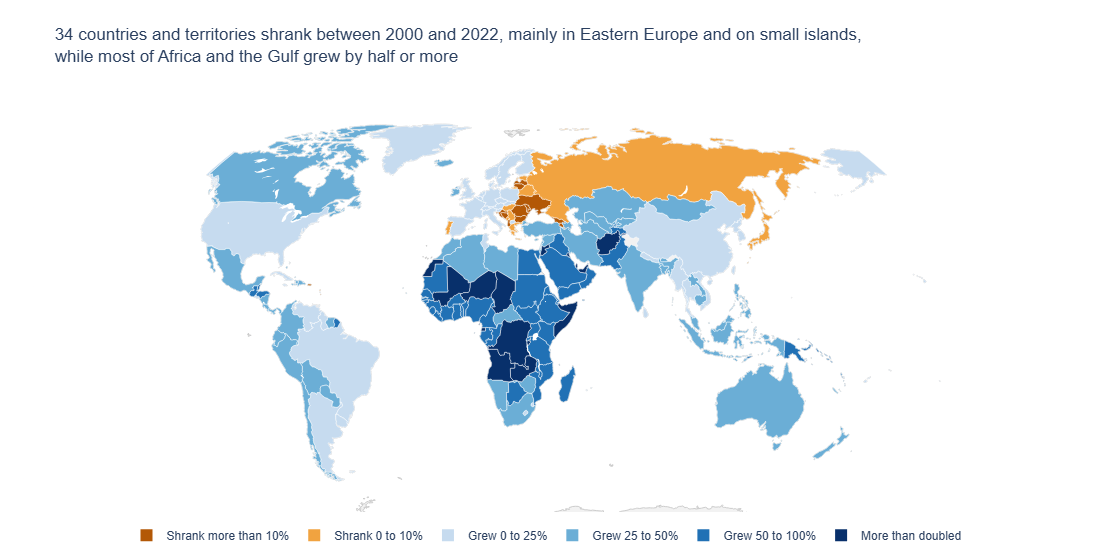

In [6]:
# Q5
# step 1: prep data, % change 2000 to 2022 grouped into diverging bins
df['Change'] = (df['2022 Population'] / df['2000 Population'] - 1) * 100
bins   = [-np.inf, -10, 0, 25, 50, 100, np.inf]
labels = ['Shrank more than 10%', 'Shrank 0 to 10%', 'Grew 0 to 25%', 'Grew 25 to 50%', 'Grew 50 to 100%', 'More than doubled']
colors = ['#B35806', '#F1A340', '#C6DBEF', '#6BAED6', '#2171B5', '#08306B']    # orange = shrank, blue = grew
df['Change group'] = pd.cut(df['Change'], bins=bins, labels=labels, right=False).astype(str)

n_shrank = (df['Change'] < 0).sum()
print(df['Change group'].value_counts().reindex(labels))
print(df.loc[df['Change'] < 0].sort_values('Change')[['Country', 'Continent', 'Change']].round(1).to_string())

# step 2: plotly express figure
fig = px.choropleth(
    data_frame=df,
    locations='CCA3', locationmode='ISO-3',
    color='Change group',
    color_discrete_map=dict(zip(labels, colors)),
    category_orders={'Change group': labels},
    hover_name='Country',
    hover_data={'CCA3': False, 'Change group': False, 'Change': ':+.1f',
                '2000 Population': ':,', '2022 Population': ':,'},
    labels={'Change': 'Change 2000 to 2022 (%)', 'Change group': ''},
    title=(f"{n_shrank} countries and territories shrank between 2000 and 2022, mainly in Eastern Europe and on small islands,<br>"
           f"while most of Africa and the Gulf grew by half or more"),
    template='plotly_white',
    height=550
)

# step 3: customisation
fig.update_traces(marker_line_color='white', marker_line_width=0.5)
fig.update_layout(
    font=dict(family='Arial', size=12),
    geo=dict(showframe=False, showcoastlines=True, coastlinecolor='#CCCCCC',
             projection_type='natural earth', showland=True, landcolor='#F2F2F2'),
    legend=dict(orientation='h', x=0.5, xanchor='center', y=-0.02, title=''),
    margin=dict(l=0, r=0, t=80, b=0)
)

fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** Treemap

- A treemap graph illustrates components of a whole at two different levels (continents and countries) on one graph.
- Box size represents population, hence larger countries get bigger boxes.
- A stacked bar cannot accommodate 234 countries, while a treemap can.
- Asia, Africa, and Europe retain their colors from the other graphs. The rest are grey.
- Every box indicates its percentage of world population.

Continent
Asia             59.2
Africa           17.9
Europe            9.3
North America     7.5
South America     5.5
Oceania           0.6
Name: Population, dtype: float64 
China + India: 35.7%


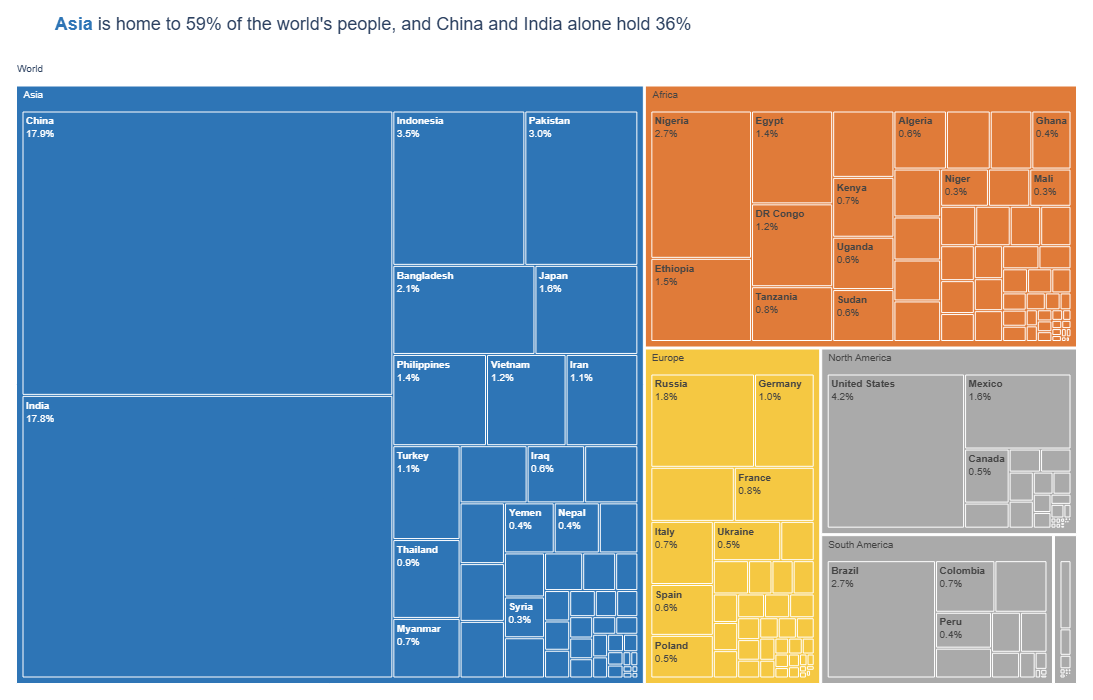

In [7]:
# Q6
# step 1: prep data
pop22 = df.rename(columns={'2022 Population': 'Population'})
cont_share = pop22.groupby('Continent')['Population'].sum() / pop22['Population'].sum() * 100
china_india = pop22.loc[pop22['Country'].isin(['China', 'India']), 'Population'].sum() / pop22['Population'].sum() * 100
print(cont_share.sort_values(ascending=False).round(1), f'\nChina + India: {china_india:.1f}%')

continent_colors = {'Asia': BLUE, 'Africa': ORANGE, 'Europe': YELLOW,
                    'North America': GREY, 'South America': GREY, 'Oceania': GREY}

# step 2: plotly express figure
fig = px.treemap(
    data_frame=pop22,
    path=[px.Constant('World'), 'Continent', 'Country'],
    values='Population',                       # additive, sums correctly at every level
    color='Continent',
    color_discrete_map={**continent_colors, '(?)': 'white'},
    template='plotly_white',
    height=700
)

# step 3: customisation
fig.update_traces(
    texttemplate='<b>%{label}</b><br>%{percentRoot:.1%}',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} people<br>%{percentRoot:.1%} of world<br>%{percentParent:.1%} of %{parent}<extra></extra>',
    marker=dict(line=dict(color='white', width=1)),
    root_color='white',
    tiling=dict(pad=2)
)

fig.update_layout(
    title=(f"<span style='color:{BLUE}'><b>Asia</b></span> is home to {cont_share['Asia']:.0f}% of the world's people, "
           f"and China and India alone hold {china_india:.0f}%"),
    font=dict(family='Arial', size=13),
    uniformtext=dict(minsize=10, mode='hide'),    # hide labels that would be too small to read
    margin=dict(l=10, r=10, t=60, b=10)
)

fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** 100% stacked bar chart

- The question relates to parts of a whole, and 100% stacked bar charts depict the changes in these parts.
- Africa appears at the bottom and Europe at the top, hence making the two largest changes easily comparable.
- Years run from left to right in a sequence. There is a footnote that explains that years are not evenly spaced.
- Percentages are indicated in the bar itself, while labels replace the legend.
- "Rest of the world" is in grey because it is simply background information.

Group  Africa  Asia  Europe  Rest of the world
Year                                          
1970      9.9  58.1    17.8               14.3
1980     10.8  59.3    15.6               14.2
1990     12.0  60.4    13.6               14.0
2000     13.3  60.8    11.8               14.1
2010     15.1  60.4    10.5               13.9
2015     16.2  60.0    10.0               13.8
2020     17.4  59.5     9.5               13.6
2022     17.9  59.2     9.3               13.6


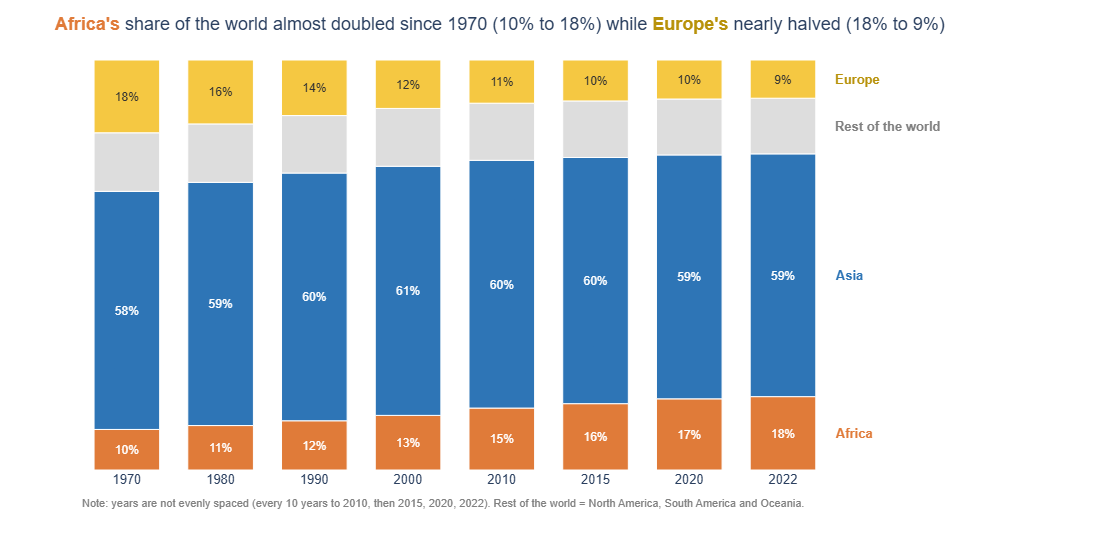

In [8]:
# Q7
# step 1: prep data, group the other three continents and compute shares of each year's world total
named = ['Africa', 'Asia', 'Europe']
grp = df_long.assign(Group=df_long['Continent'].where(df_long['Continent'].isin(named), 'Rest of the world'))
share = grp.groupby(['Year', 'Group'], as_index=False)['Population'].sum()
share['Share'] = share['Population'] / share.groupby('Year')['Population'].transform('sum')
share['Label'] = np.where(share['Group'] == 'Rest of the world', '', share['Share'].map('{:.0%}'.format))
share['Year'] = share['Year'].astype(str)                 # categorical axis: one bar per survey year

s = share.pivot(index='Year', columns='Group', values='Share')
print((s * 100).round(1))

order = ['Africa', 'Asia', 'Rest of the world', 'Europe']   # Africa on the baseline, Europe anchored at 100%
group_colors = {'Africa': ORANGE, 'Asia': BLUE, 'Europe': YELLOW, 'Rest of the world': LIGHT_GREY}

# step 2: plotly express figure
fig = px.bar(
    data_frame=share,
    x='Year', y='Share',
    color='Group',
    text='Label',
    color_discrete_map=group_colors,
    category_orders={'Group': order},
    hover_data={'Label': False, 'Share': ':.1%', 'Population': ':,'},
    template='plotly_white',
    height=550
)

# step 3: customisation
fig.update_traces(textposition='inside', insidetextanchor='middle', textfont=dict(size=12),
                  marker_line_color='white', marker_line_width=1)
fig.update_traces(selector={'name': 'Africa'}, textfont_color='white')
fig.update_traces(selector={'name': 'Asia'}, textfont_color='white')
fig.update_traces(selector={'name': 'Europe'}, textfont_color='#333333')

# direct labels to the right of the 2022 column, centred on each segment
# (x is the category index of the last bar: a numeric-looking string like '2022' would be read as index 2022)
last = s.loc['2022', order].cumsum() - s.loc['2022', order] / 2
label_color = {'Africa': ORANGE, 'Asia': BLUE, 'Europe': '#B8920A', 'Rest of the world': 'grey'}
for g in order:
    fig.add_annotation(x=len(s) - 1, y=last[g], text=f'<b>{g}</b>', showarrow=False,
                       xanchor='left', xshift=50, font=dict(size=13, color=label_color[g]))

fig.add_annotation(xref='paper', yref='paper', x=0, y=-0.1, showarrow=False, xanchor='left',
                   text='Note: years are not evenly spaced (every 10 years to 2010, then 2015, 2020, 2022). Rest of the world = North America, South America and Oceania.',
                   font=dict(size=11, color='grey'))

fig.update_layout(
    title=(f"<span style='color:{ORANGE}'><b>Africa's</b></span> share of the world almost doubled since 1970 "
           f"({s.loc['1970', 'Africa']:.0%} to {s.loc['2022', 'Africa']:.0%}) while "
           f"<span style='color:#B8920A'><b>Europe's</b></span> nearly halved ({s.loc['1970', 'Europe']:.0%} to {s.loc['2022', 'Europe']:.0%})"),
    showlegend=False,
    font=dict(family='Arial', size=13),
    bargap=0.3,
    xaxis=dict(title='', showgrid=False, type='category'),   # year strings would otherwise be read as numbers
    yaxis=dict(visible=False, range=[0, 1]),
    margin=dict(r=150, b=80)
)

fig.show()